Khởi tạo

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle 
train=pd.read_csv('train.csv')
test=pd.read_csv('test.csv')
print('Train Shape: ',train.shape)
print('Test Shape: ',test.shape)
print(train.info())
print(test.info())


Train Shape:  (1460, 81)
Test Shape:  (1459, 80)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual   

Đọc dữ liệu từ tập

In [76]:
train=pd.read_csv('train.csv')
test=pd.read_csv('test.csv')

In [77]:

train.describe()
train.describe(include='all')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,...,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,...,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,...,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,...,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,...,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,...,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,1.000000,2006.000000,NaN,NaN,34900.000000
25%,365.750000,20.000000,NaN,59.000000,7553.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,5.000000,2007.000000,NaN,NaN,129975.000000
50%,730.500000,50.000000,NaN,69.000000,9478.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,6.000000,2008.000000,NaN,NaN,163000.000000
75%,1095.250000,70.000000,NaN,80.000000,11601.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,8.000000,2009.000000,NaN,NaN,214000.000000


Thống kê giá trị bị thiếu trong dữ liệu

In [78]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [79]:
train['SalePrice'].describe()
train['SalePrice'].skew()

np.float64(1.8828757597682129)

Phân tích hệ số tương quan giữa các thuộc tính số và SalePrice

In [80]:
numeric_cols = train.select_dtypes(include=['int64', 'float64'])

corr = numeric_cols.corr()

corr['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

Top 15 thuộc tính có tương quan mạnh nhất với SalePrice

In [81]:
corr_saleprice = corr['SalePrice'].abs().sort_values(ascending=False)

corr_saleprice.head(15)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

Kiểm tra các giá trị bất thường của GrLivArea

In [82]:
train[['Id', 'GrLivArea', 'OverallQual', 'SalePrice']].sort_values(
    by='GrLivArea',
    ascending=False
).head(10)

,Id,GrLivArea,OverallQual,SalePrice
1298,1299,5642,10,160000
523,524,4676,10,184750
1182,1183,4476,10,745000
691,692,4316,10,755000
1169,1170,3627,10,625000
185,186,3608,10,475000
304,305,3493,7,295000
1268,1269,3447,8,381000
635,636,3395,6,200000
769,770,3279,8,538000


Xác định giá trị ngoại lệ của SalePrice bằng phương pháp IQR

In [83]:

Q1 = train['SalePrice'].quantile(0.25)
Q3 = train['SalePrice'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = train[
    (train['SalePrice'] < lower) |
    (train['SalePrice'] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower:", lower)
print("Upper:", upper)
print("Số lượng outlier:", len(outliers))

Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Lower: 3937.5
Upper: 340037.5
Số lượng outlier: 61


Thống kê và xác định các thuộc tính dữ liệu số

In [84]:
# Lấy các thuộc tính có kiểu dữ liệu số
numeric_data = train.select_dtypes(include=['int64', 'float64'])
print("Số thuộc tính số:", numeric_data.shape[1])
print("Danh sách thuộc tính số:")
print(numeric_data.columns.tolist())
# Số lượng thuộc tính số
print("\nSố lượng thuộc tính số:", numeric_data.shape[1])

Số thuộc tính số: 38
Danh sách thuộc tính số:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Số lượng thuộc tính số: 38


In [85]:
# Thống kê mô tả các thuộc tính số
stats = numeric_data.describe()

stats

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [86]:
# Tính median và IQR
median = numeric_data.median()
Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

statistical_summary = pd.DataFrame({
    'Mean': numeric_data.mean(),
    'Median': median,
    'Std': numeric_data.std(),
    'Min': numeric_data.min(),
    'Q1': Q1,
    'Q3': Q3,
    'Max': numeric_data.max(),
    'IQR': IQR
})

statistical_summary

,Mean,Median,Std,Min,Q1,Q3,Max,IQR
Id,730.500000,730.5,421.610009,1.0,365.75,1095.25,1460.0,729.50
MSSubClass,56.897260,50.0,42.300571,20.0,20.00,70.00,190.0,50.00
LotFrontage,70.049958,69.0,24.284752,21.0,59.00,80.00,313.0,21.00
LotArea,10516.828082,9478.5,9981.264932,1300.0,7553.50,11601.50,215245.0,4048.00
OverallQual,6.099315,6.0,1.382997,1.0,5.00,7.00,10.0,2.00
OverallCond,5.575342,5.0,1.112799,1.0,5.00,6.00,9.0,1.00
YearBuilt,1971.267808,1973.0,30.202904,1872.0,1954.00,2000.00,2010.0,46.00
YearRemodAdd,1984.865753,1994.0,20.645407,1950.0,1967.00,2004.00,2010.0,37.00
MasVnrArea,103.685262,0.0,181.066207,0.0,0.00,166.00,1600.0,166.00
BsmtFinSF1,443.639726,383.5,456.098091,0.0,0.00,712.25,5644.0,712.25


In [87]:
skewness = numeric_data.skew()

skewness.sort_values(ascending=False)


MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
MasVnrArea        2.669084
OpenPorchSF       2.364342
LotFrontage       2.163569
SalePrice         1.882876
BsmtFinSF1        1.685503
WoodDeckSF        1.541376
TotalBsmtSF       1.524255
MSSubClass        1.407657
1stFlrSF          1.376757
GrLivArea         1.366560
BsmtUnfSF         0.920268
2ndFlrSF          0.813030
OverallCond       0.693067
TotRmsAbvGrd      0.676341
HalfBath          0.675897
Fireplaces        0.649565
BsmtFullBath      0.596067
OverallQual       0.216944
MoSold            0.212053
BedroomAbvGr      0.211790
GarageArea        0.179981
YrSold            0.096269
FullBath          0.036562
Id                0.000000
GarageCars       -0.342549
YearRemodAdd     -0.503562
YearBuilt        -0.613461
G

Thống kê mô tả biến mục tiêu SalePrice

In [88]:
saleprice_stats = train['SalePrice'].describe()

saleprice_stats
print("Mean:", train['SalePrice'].mean())
print("Median:", train['SalePrice'].median())
print("Std:", train['SalePrice'].std())
print("Min:", train['SalePrice'].min())
print("Max:", train['SalePrice'].max())
print("Skewness:", train['SalePrice'].skew())

Mean: 180921.19589041095
Median: 163000.0
Std: 79442.50288288662
Min: 34900
Max: 755000
Skewness: 1.8828757597682129


Phân phối SalePrice

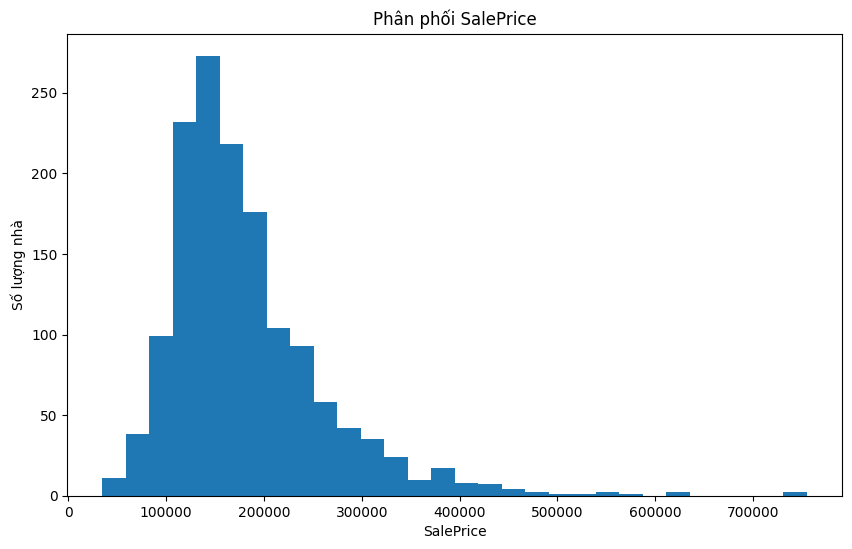

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(train['SalePrice'], bins=30)

plt.title('Phân phối SalePrice')
plt.xlabel('SalePrice')
plt.ylabel('Số lượng nhà')

plt.show()

BoxPlot

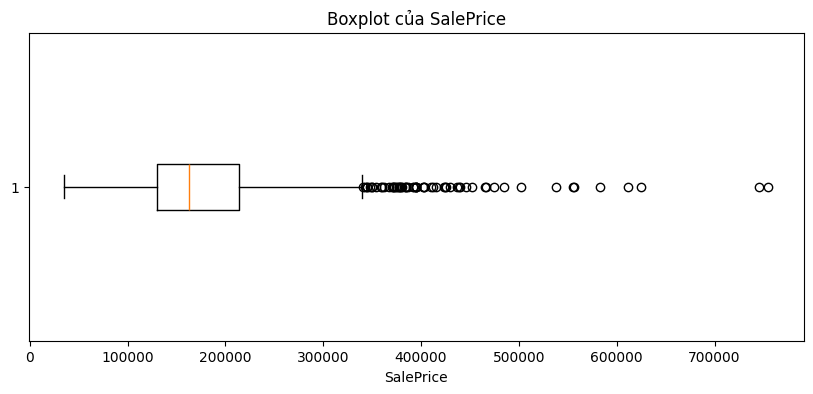

In [90]:
plt.figure(figsize=(10, 4))

plt.boxplot(train['SalePrice'], vert=False)

plt.title('Boxplot của SalePrice')
plt.xlabel('SalePrice')

plt.show()

Độ lệch phân phối

In [91]:
skewness = numeric_data.skew()

skewness.sort_values(ascending=False)

MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
MasVnrArea        2.669084
OpenPorchSF       2.364342
LotFrontage       2.163569
SalePrice         1.882876
BsmtFinSF1        1.685503
WoodDeckSF        1.541376
TotalBsmtSF       1.524255
MSSubClass        1.407657
1stFlrSF          1.376757
GrLivArea         1.366560
BsmtUnfSF         0.920268
2ndFlrSF          0.813030
OverallCond       0.693067
TotRmsAbvGrd      0.676341
HalfBath          0.675897
Fireplaces        0.649565
BsmtFullBath      0.596067
OverallQual       0.216944
MoSold            0.212053
BedroomAbvGr      0.211790
GarageArea        0.179981
YrSold            0.096269
FullBath          0.036562
Id                0.000000
GarageCars       -0.342549
YearRemodAdd     -0.503562
YearBuilt        -0.613461
G

Xác định giá trị ngoại lai

In [92]:
numeric_data = train.select_dtypes(include=['int64', 'float64'])

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_count = (
    (numeric_data < lower_bound) |
    (numeric_data > upper_bound)
).sum()

outlier_count = outlier_count.sort_values(ascending=False)

print(outlier_count)

EnclosedPorch    208
BsmtFinSF2       167
OverallCond      125
ScreenPorch      116
MSSubClass       103
MasVnrArea        96
LotFrontage       88
BsmtHalfBath      82
OpenPorchSF       77
LotArea           69
KitchenAbvGr      68
TotalBsmtSF       61
SalePrice         61
MiscVal           52
BedroomAbvGr      35
WoodDeckSF        32
GrLivArea         31
TotRmsAbvGrd      30
BsmtUnfSF         29
LowQualFinSF      26
3SsnPorch         24
GarageArea        21
1stFlrSF          20
BsmtFinSF1         7
YearBuilt          7
PoolArea           7
GarageCars         5
Fireplaces         5
2ndFlrSF           2
OverallQual        2
BsmtFullBath       1
Id                 0
YearRemodAdd       0
FullBath           0
HalfBath           0
GarageYrBlt        0
MoSold             0
YrSold             0
dtype: int64


Vẽ boxplot cho outliner

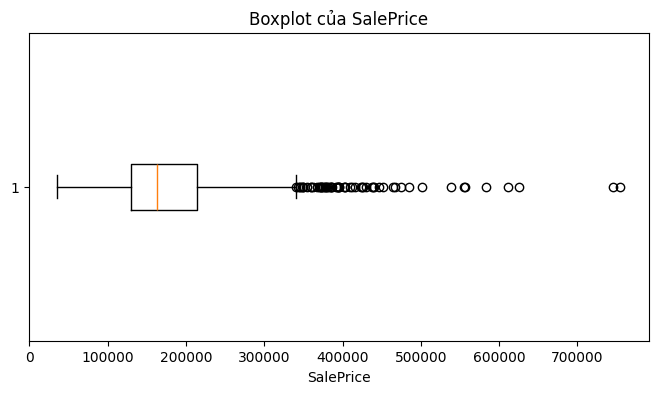

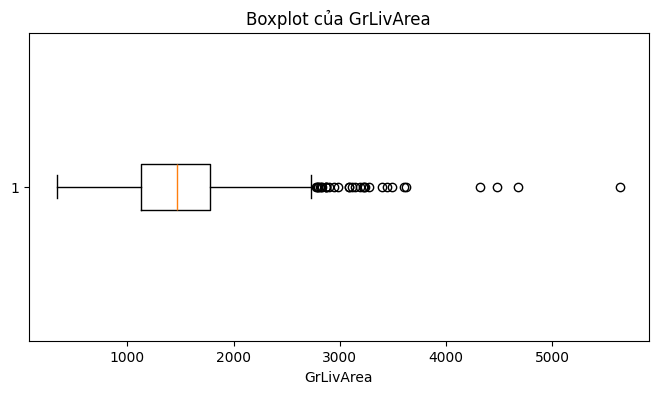

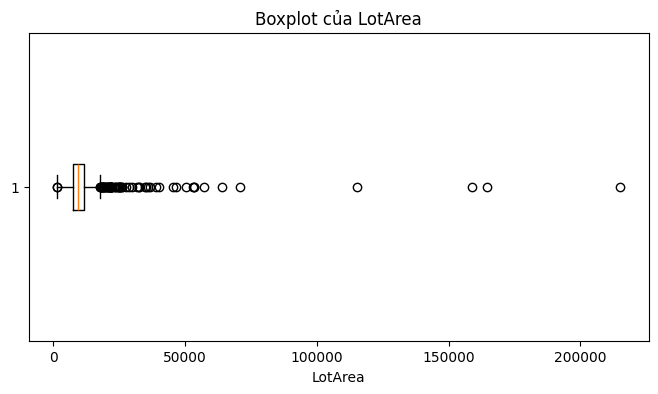

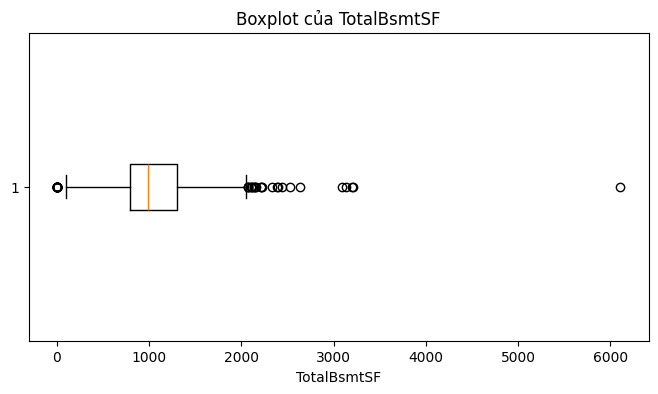

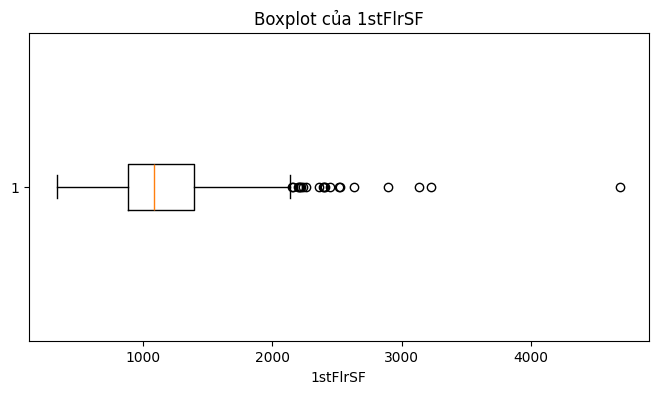

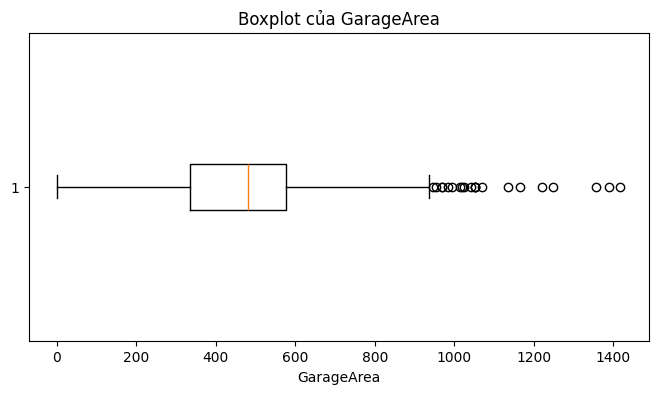

In [93]:
cols = [
    'SalePrice',
    'GrLivArea',
    'LotArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'GarageArea'
]
for col in cols:
    plt.figure(figsize=(8, 4))

    plt.boxplot(train[col].dropna(), vert=False)

    plt.title(f'Boxplot của {col}')
    plt.xlabel(col)

    plt.show()

Phân tích tương quan giữa các biến số

In [94]:
correlation = numeric_data.corr()

correlation

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


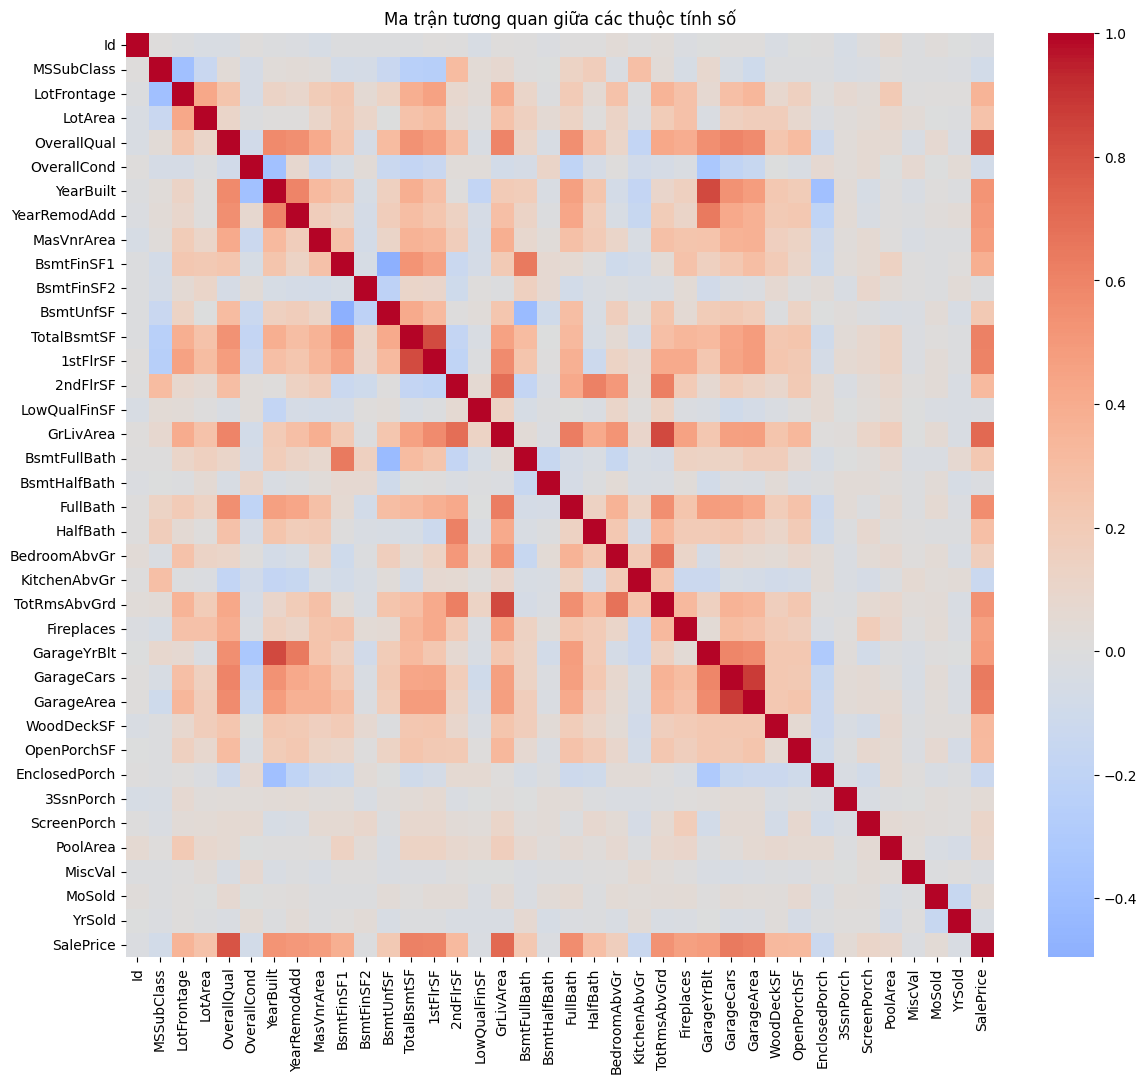

In [95]:
plt.figure(figsize=(14, 12))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0
)

plt.title('Ma trận tương quan giữa các thuộc tính số')

plt.show()

In [96]:
saleprice_corr = correlation['SalePrice'].sort_values(ascending=False)

saleprice_corr

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

In [97]:
top_features = (
    correlation['SalePrice']
    .drop('SalePrice')
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

saleprice_top_corr = correlation.loc[top_features, 'SalePrice'].sort_values(
    ascending=False
)

saleprice_top_corr

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

Ma trận tương quan

In [98]:
top_features = [
    'SalePrice',
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'GarageArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'FullBath',
    'TotRmsAbvGrd',
    'YearBuilt',
    'YearRemodAdd'
]

corr_matrix = train[top_features].corr()

corr_matrix

,SalePrice,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd
SalePrice,1.000000,0.790982,0.708624,0.640409,0.623431,0.613581,0.605852,0.560664,0.533723,0.522897,0.507101
OverallQual,0.790982,1.000000,0.593007,0.600671,0.562022,0.537808,0.476224,0.550600,0.427452,0.572323,0.550684
GrLivArea,0.708624,0.593007,1.000000,0.467247,0.468997,0.454868,0.566024,0.630012,0.825489,0.199010,0.287389
GarageCars,0.640409,0.600671,0.467247,1.000000,0.882475,0.434585,0.439317,0.469672,0.362289,0.537850,0.420622
GarageArea,0.623431,0.562022,0.468997,0.882475,1.000000,0.486665,0.489782,0.405656,0.337822,0.478954,0.371600
TotalBsmtSF,0.613581,0.537808,0.454868,0.434585,0.486665,1.000000,0.819530,0.323722,0.285573,0.391452,0.291066
1stFlrSF,0.605852,0.476224,0.566024,0.439317,0.489782,0.819530,1.000000,0.380637,0.409516,0.281986,0.240379
FullBath,0.560664,0.550600,0.630012,0.469672,0.405656,0.323722,0.380637,1.000000,0.554784,0.468271,0.439046
TotRmsAbvGrd,0.533723,0.427452,0.825489,0.362289,0.337822,0.285573,0.409516,0.554784,1.000000,0.095589,0.191740
YearBuilt,0.522897,0.572323,0.199010,0.537850,0.478954,0.391452,0.281986,0.468271,0.095589,1.000000,0.592855


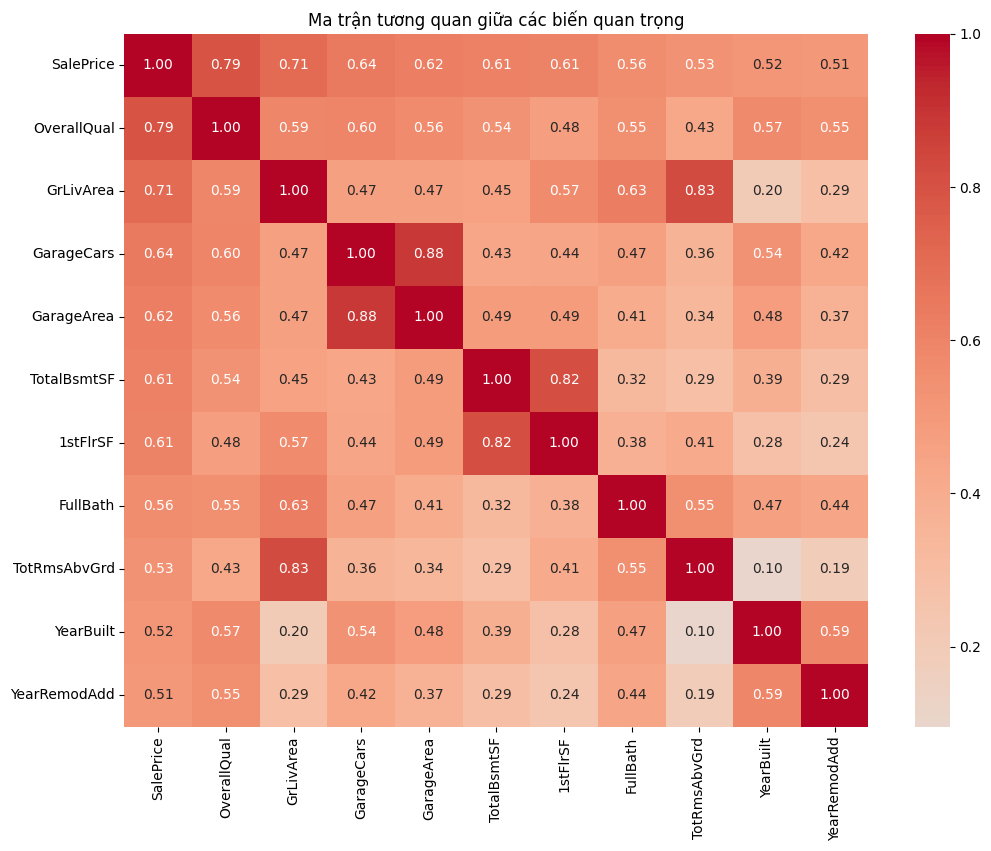

In [99]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Ma trận tương quan giữa các biến quan trọng')
plt.show()

Scatterp plot

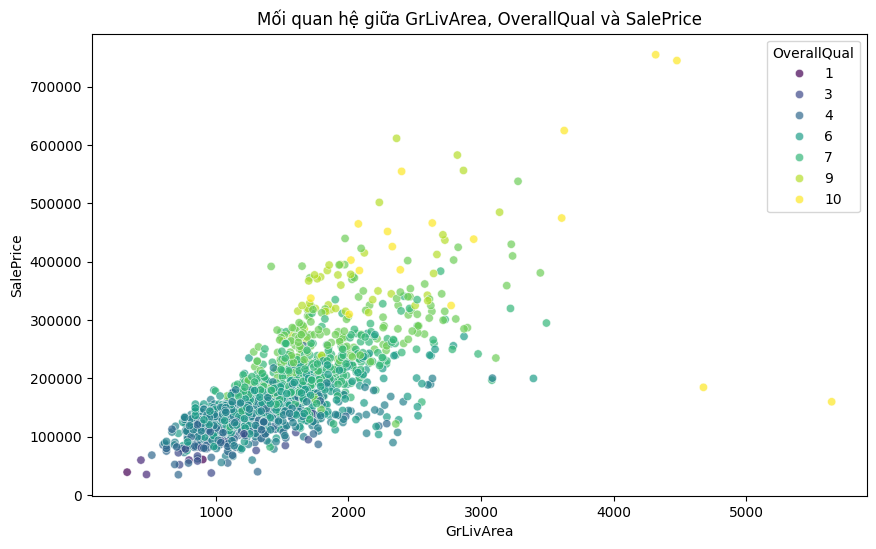

In [100]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train,
    x='GrLivArea',
    y='SalePrice',
    hue='OverallQual',
    palette='viridis',
    alpha=0.7
)

plt.title('Mối quan hệ giữa GrLivArea, OverallQual và SalePrice')
plt.xlabel('GrLivArea')
plt.ylabel('SalePrice')
plt.legend(title='OverallQual')

plt.show()

Phân tích YearBuilt, OverallQual, GrLivArea và SalePrice

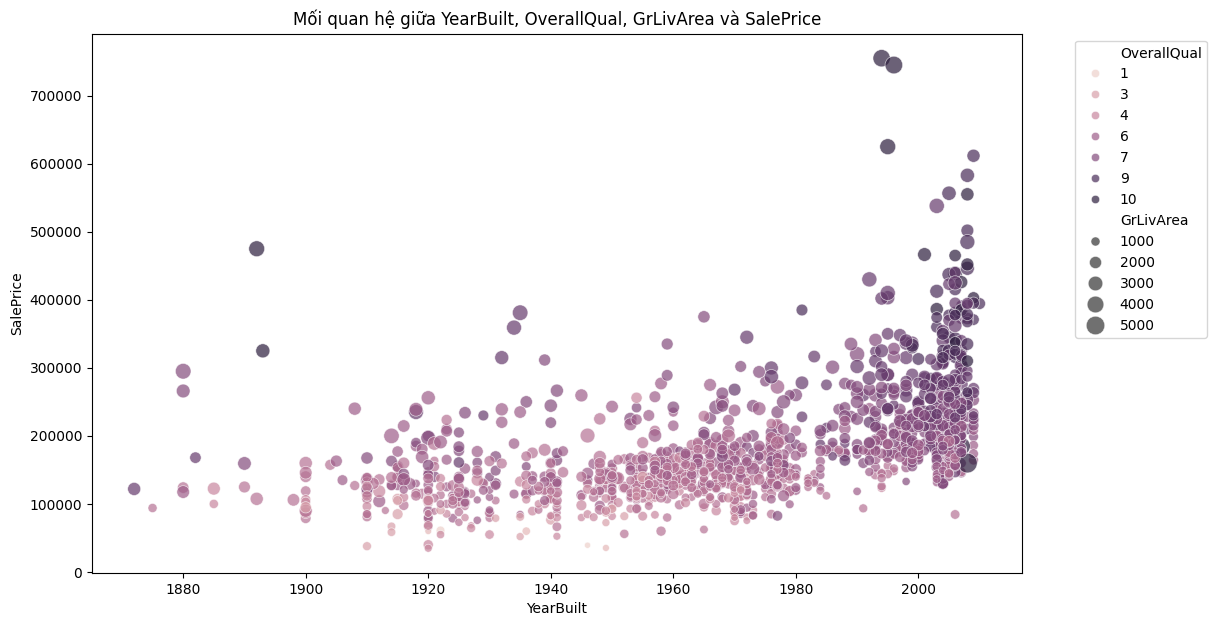

In [101]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=train,
    x='YearBuilt',
    y='SalePrice',
    hue='OverallQual',
    size='GrLivArea',
    sizes=(20, 200),
    alpha=0.7
)

plt.title('Mối quan hệ giữa YearBuilt, OverallQual, GrLivArea và SalePrice')
plt.xlabel('YearBuilt')
plt.ylabel('SalePrice')

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.show()

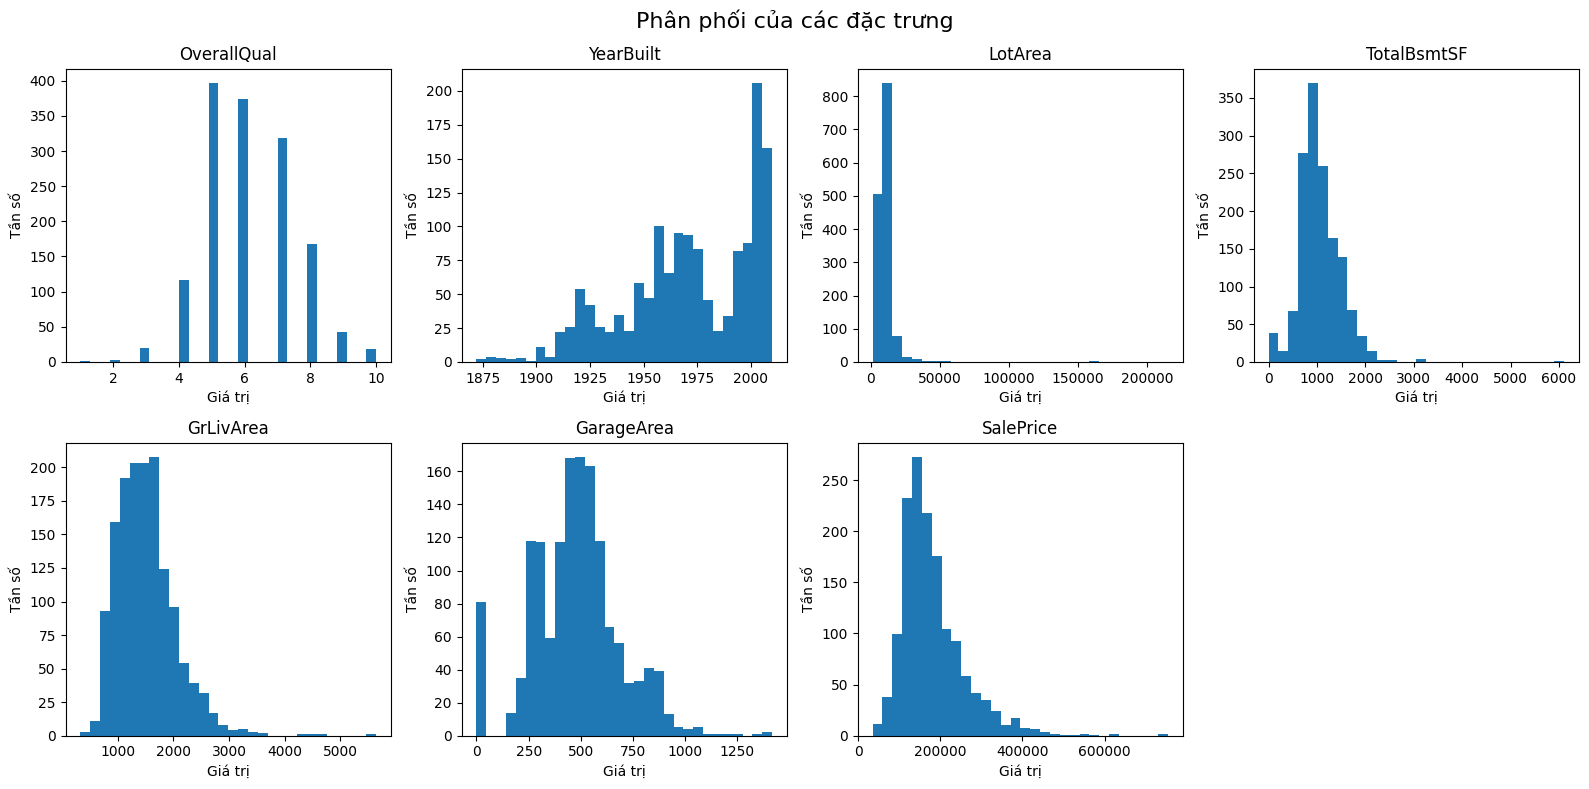

In [102]:
import matplotlib.pyplot as plt

features = [
    'OverallQual',
    'YearBuilt',
    'LotArea',
    'TotalBsmtSF',
    'GrLivArea',
    'GarageArea',
    'SalePrice'
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes = axes.flatten()

for i, feature in enumerate(features):
    axes[i].hist(train[feature], bins=30)
    
    axes[i].set_title(feature)
    axes[i].set_xlabel('Giá trị')
    axes[i].set_ylabel('Tần số')
    
# Xóa ô thừa
axes[-1].axis('off')

plt.suptitle('Phân phối của các đặc trưng', fontsize=16)

plt.tight_layout()
plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_27020\637203470.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


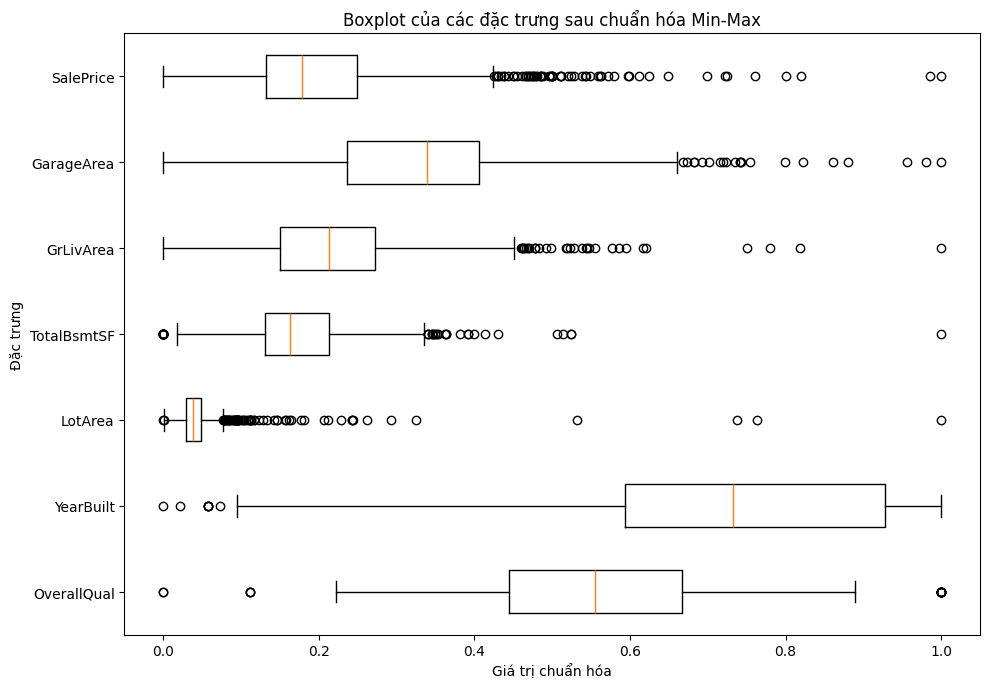

In [103]:
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

features = [
    'OverallQual',
    'YearBuilt',
    'LotArea',
    'TotalBsmtSF',
    'GrLivArea',
    'GarageArea',
    'SalePrice'
]

data = train[features].dropna()

scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data)

plt.figure(figsize=(10, 7))

plt.boxplot(
    data_scaled,
    labels=features,
    vert=False
)

plt.title('Boxplot của các đặc trưng sau chuẩn hóa Min-Max')
plt.xlabel('Giá trị chuẩn hóa')
plt.ylabel('Đặc trưng')

plt.tight_layout()
plt.show()

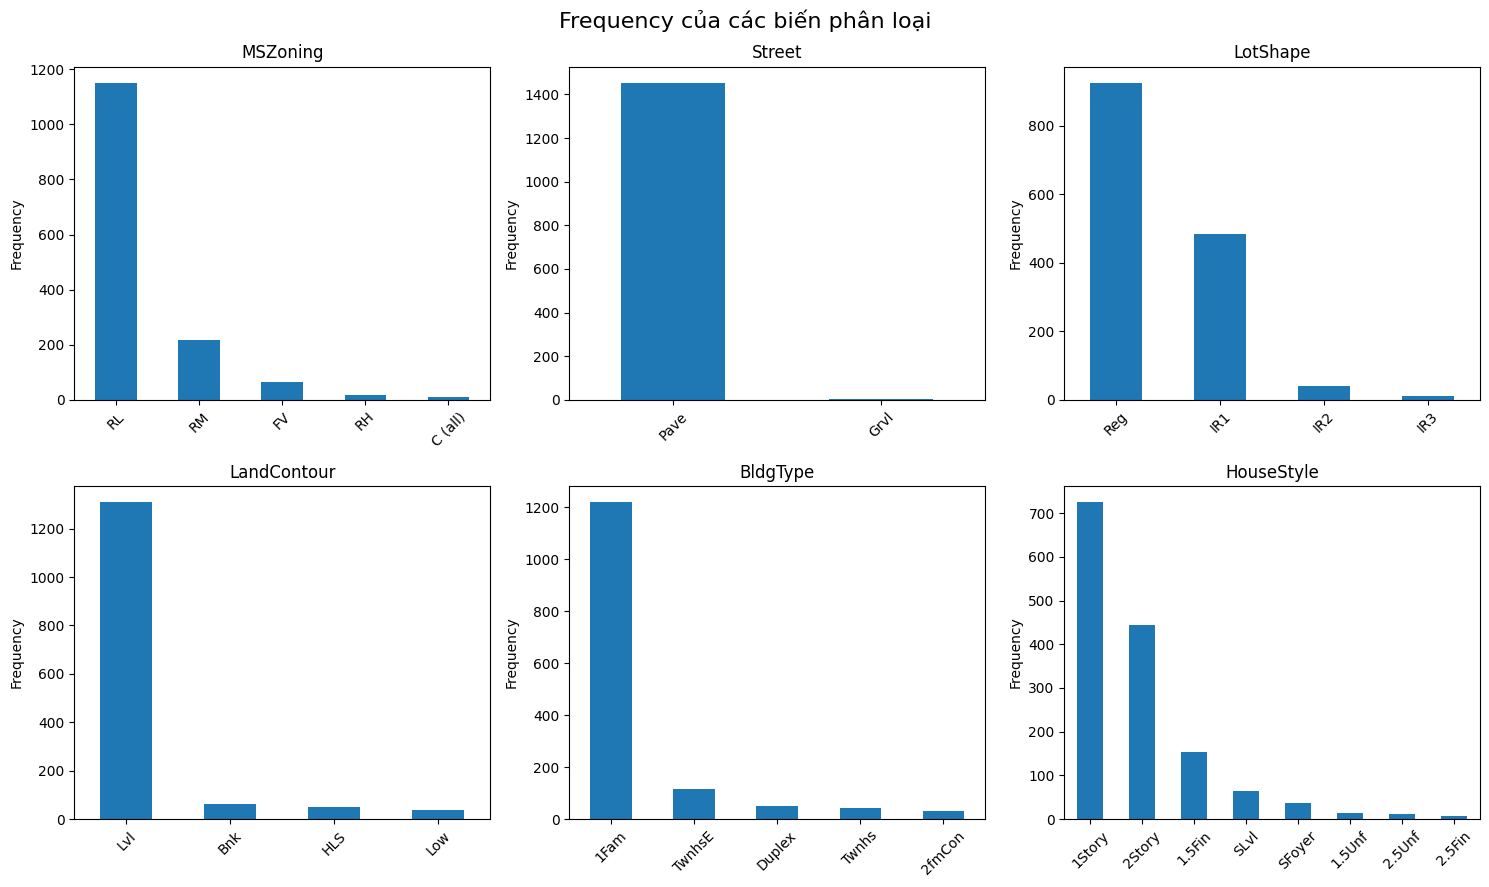

In [104]:
categorical_features = [
    'MSZoning',
    'Street',
    'LotShape',
    'LandContour',
    'BldgType',
    'HouseStyle'
]
import matplotlib.pyplot as plt

categorical_features = [
    'MSZoning',
    'Street',
    'LotShape',
    'LandContour',
    'BldgType',
    'HouseStyle'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    
    train[feature].value_counts().plot(
        kind='bar',
        ax=axes[i]
    )
    
    axes[i].set_title(feature)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle(
    'Frequency của các biến phân loại',
    fontsize=16
)

plt.tight_layout()
plt.show()

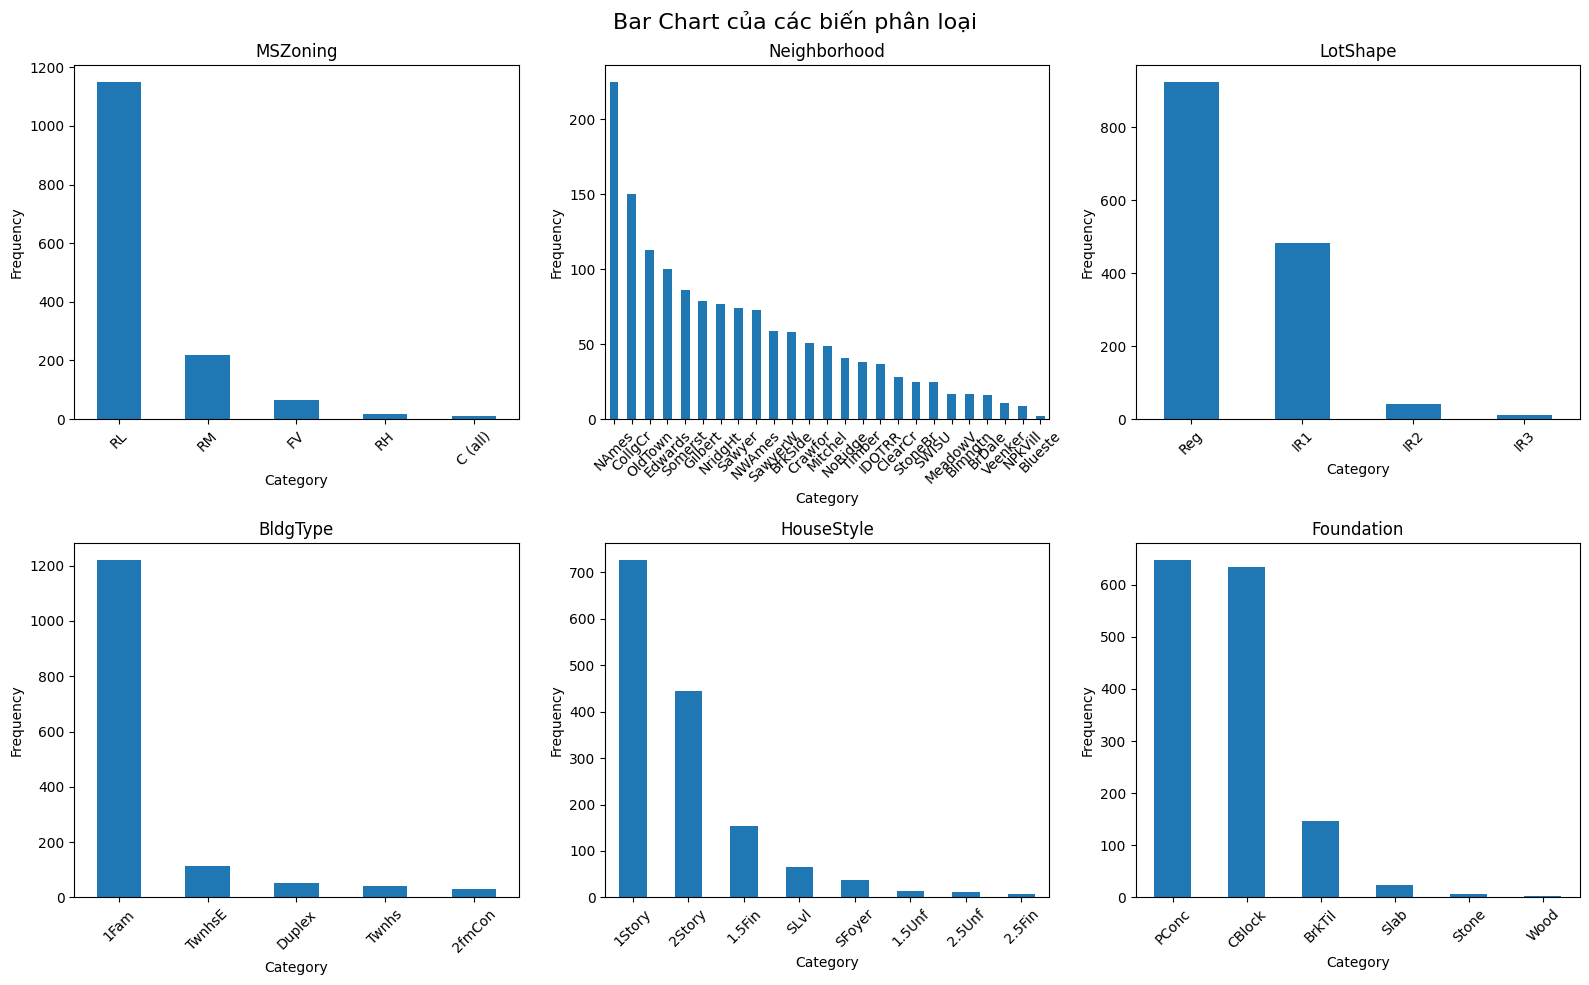

In [105]:
import matplotlib.pyplot as plt

categorical_features = [
    'MSZoning',
    'Neighborhood',
    'LotShape',
    'BldgType',
    'HouseStyle',
    'Foundation'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    train[feature].value_counts().plot(
        kind='bar',
        ax=axes[i]
    )
    
    axes[i].set_title(feature)
    axes[i].set_xlabel('Category')
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle(
    'Bar Chart của các biến phân loại',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [106]:
pairs = [
    ('GrLivArea', 'SalePrice'),
    ('OverallQual', 'SalePrice'),
    ('TotalBsmtSF', 'SalePrice'),
    ('YearBuilt', 'SalePrice'),
    ('GarageArea', 'SalePrice')
]

for x, y in pairs:
    correlation = train[x].corr(train[y])
    print(f"{x} vs {y}: {correlation:.4f}")

GrLivArea vs SalePrice: 0.7086
OverallQual vs SalePrice: 0.7910
TotalBsmtSF vs SalePrice: 0.6136
YearBuilt vs SalePrice: 0.5229
GarageArea vs SalePrice: 0.6234


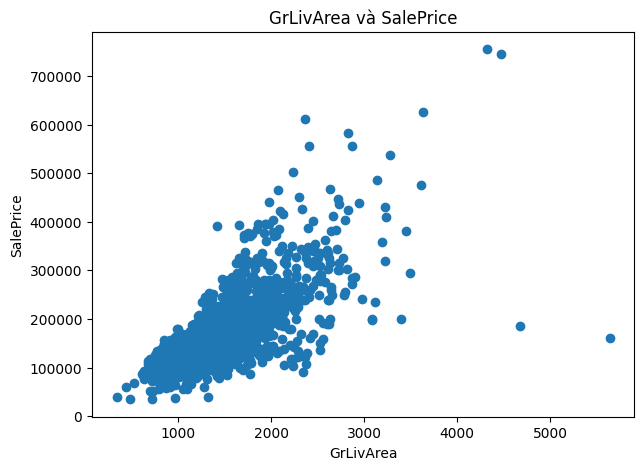

In [107]:
plt.figure(figsize=(7, 5))

plt.scatter(train['GrLivArea'], train['SalePrice'])

plt.title('GrLivArea và SalePrice')
plt.xlabel('GrLivArea')
plt.ylabel('SalePrice')

plt.show()

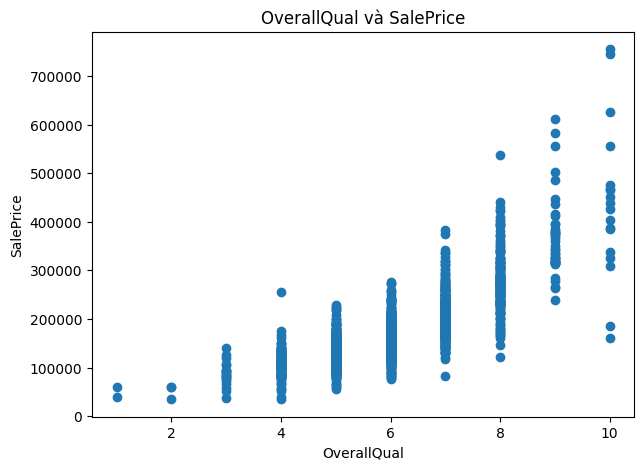

In [108]:
plt.figure(figsize=(7, 5))

plt.scatter(train['OverallQual'], train['SalePrice'])

plt.title('OverallQual và SalePrice')
plt.xlabel('OverallQual')
plt.ylabel('SalePrice')

plt.show()

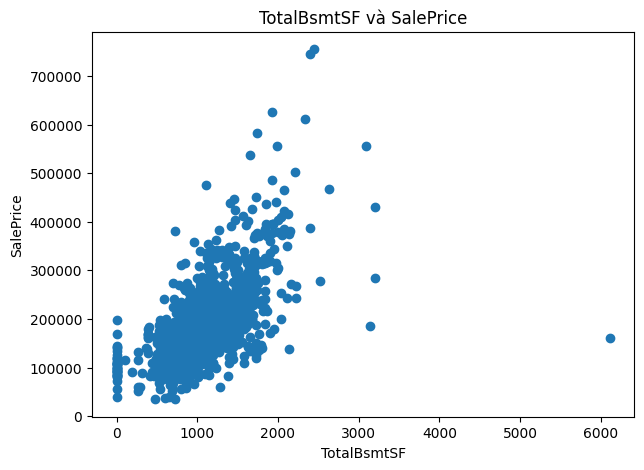

In [109]:
plt.figure(figsize=(7, 5))

plt.scatter(train['TotalBsmtSF'], train['SalePrice'])

plt.title('TotalBsmtSF và SalePrice')
plt.xlabel('TotalBsmtSF')
plt.ylabel('SalePrice')

plt.show()

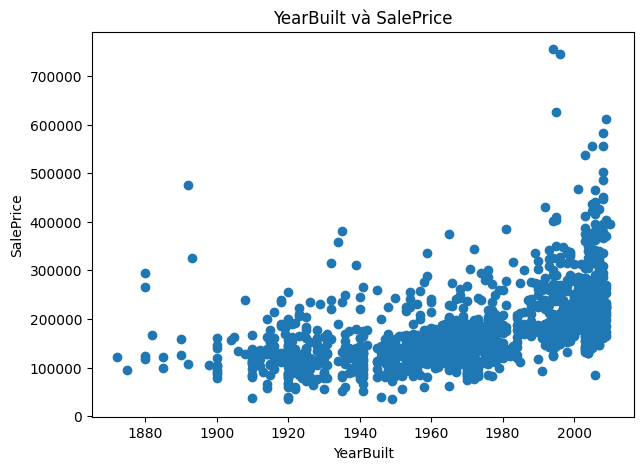

In [110]:
plt.figure(figsize=(7, 5))

plt.scatter(train['YearBuilt'], train['SalePrice'])

plt.title('YearBuilt và SalePrice')
plt.xlabel('YearBuilt')
plt.ylabel('SalePrice')

plt.show()

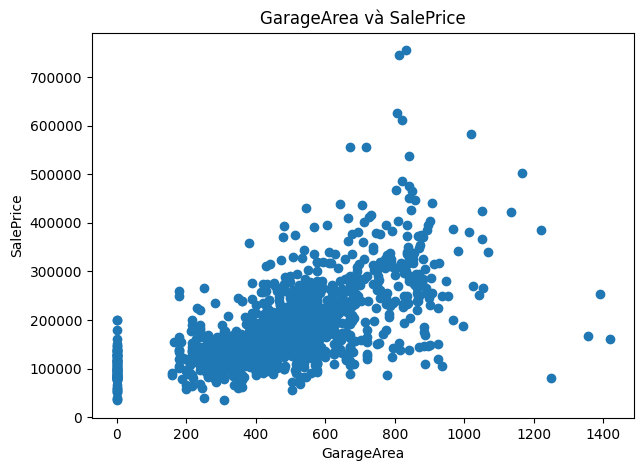

In [111]:
plt.figure(figsize=(7, 5))

plt.scatter(train['GarageArea'], train['SalePrice'])

plt.title('GarageArea và SalePrice')
plt.xlabel('GarageArea')
plt.ylabel('SalePrice')

plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_27020\904186815.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


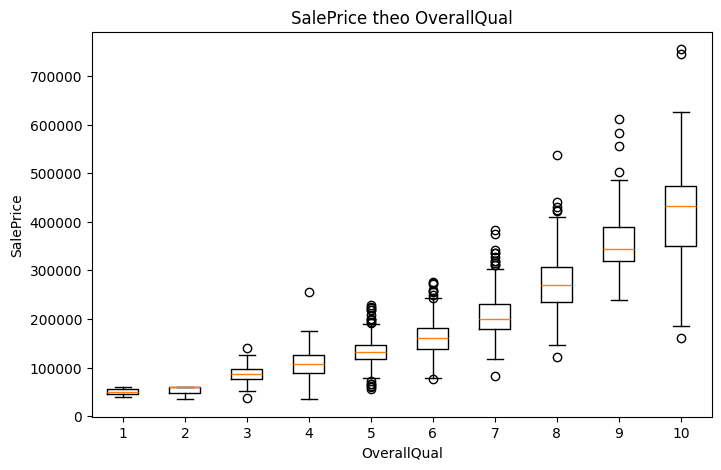

In [112]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.boxplot(
    [train[train['OverallQual'] == i]['SalePrice'] for i in sorted(train['OverallQual'].unique())],
    labels=sorted(train['OverallQual'].unique())
)

plt.title('SalePrice theo OverallQual')
plt.xlabel('OverallQual')
plt.ylabel('SalePrice')

plt.show()

In [113]:
stats_overallqual = train.groupby('OverallQual')['SalePrice'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

stats_overallqual

,count,mean,median,std,min,max
OverallQual,,,,,,
1,2,50150.00,50150.0,15344.22,39300,61000
2,3,51770.33,60000.0,14254.20,35311,60000
3,20,87473.75,86250.0,24688.57,37900,139600
4,116,108420.66,108000.0,29022.00,34900,256000
5,397,133523.35,133000.0,27107.33,55993,228950
6,374,161603.03,160000.0,36090.18,76000,277000
7,319,207716.42,200141.0,44466.26,82500,383970
8,168,274735.54,269750.0,63898.90,122000,538000
9,43,367513.02,345000.0,81278.17,239000,611657


C:\Users\admin\AppData\Local\Temp\ipykernel_27020\904186815.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


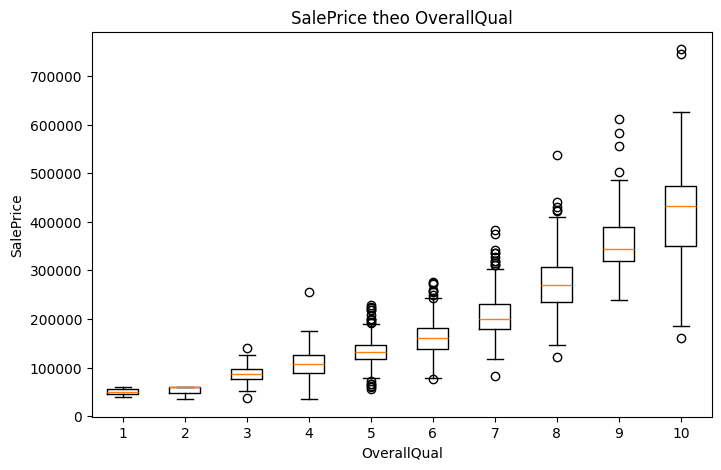

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.boxplot(
    [train[train['OverallQual'] == i]['SalePrice'] for i in sorted(train['OverallQual'].unique())],
    labels=sorted(train['OverallQual'].unique())
)

plt.title('SalePrice theo OverallQual')
plt.xlabel('OverallQual')
plt.ylabel('SalePrice')

plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_27020\1008755670.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=groups)


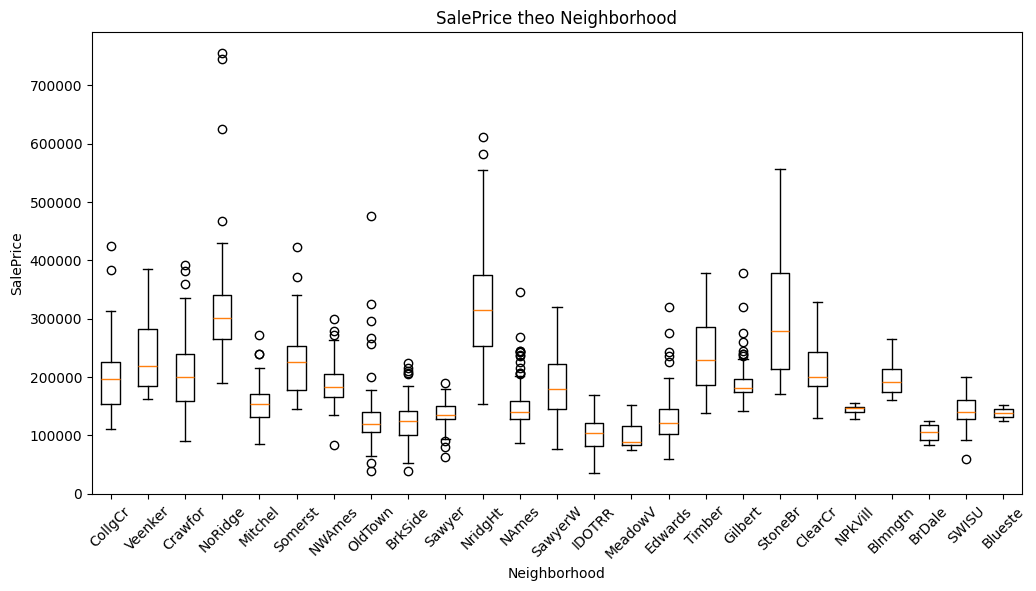

In [115]:
import matplotlib.pyplot as plt

groups = train['Neighborhood'].unique()

data = [
    train[train['Neighborhood'] == group]['SalePrice']
    for group in groups
]

plt.figure(figsize=(12, 6))

plt.boxplot(data, labels=groups)

plt.title('SalePrice theo Neighborhood')
plt.xlabel('Neighborhood')
plt.ylabel('SalePrice')

plt.xticks(rotation=45)

plt.show()

In [116]:
stats_neighborhood = train.groupby('Neighborhood')['SalePrice'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

stats_neighborhood

,count,mean,median,std,min,max
Neighborhood,,,,,,
Blmngtn,17,194870.88,191000.0,30393.23,159895,264561
Blueste,2,137500.00,137500.0,19091.88,124000,151000
BrDale,16,104493.75,106000.0,14330.18,83000,125000
BrkSide,58,124834.05,124300.0,40348.69,39300,223500
ClearCr,28,212565.43,200250.0,50231.54,130000,328000
CollgCr,150,197965.77,197200.0,51403.67,110000,424870
Crawfor,51,210624.73,200624.0,68866.40,90350,392500
Edwards,100,128219.70,121750.0,43208.62,58500,320000
Gilbert,79,192854.51,181000.0,35986.78,141000,377500


In [117]:
stats_housestyle = train.groupby('HouseStyle')['SalePrice'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

stats_housestyle

,count,mean,median,std,min,max
HouseStyle,,,,,,
1.5Fin,154,143116.74,132000.0,54277.94,37900,410000
1.5Unf,14,110150.00,111250.0,19036.47,76000,139400
1Story,726,175985.48,154750.0,77055.72,34900,611657
2.5Fin,8,220000.00,194000.0,118211.98,104000,475000
2.5Unf,11,157354.55,133900.0,63934.13,101000,325000
2Story,445,210051.76,190000.0,87339.21,40000,755000
SFoyer,37,135074.49,135960.0,30480.90,75500,206300
SLvl,65,166703.38,164500.0,38305.16,91000,345000


C:\Users\admin\AppData\Local\Temp\ipykernel_27020\1719968359.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=groups)


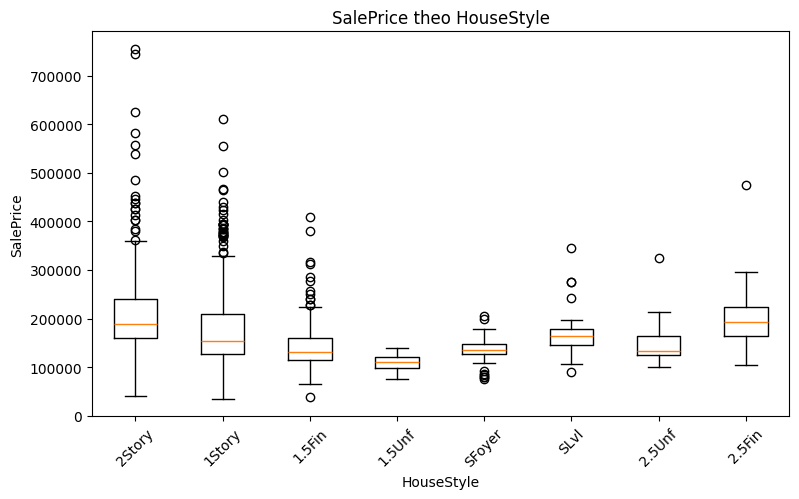

In [118]:
import matplotlib.pyplot as plt

groups = train['HouseStyle'].unique()

data = [
    train[train['HouseStyle'] == group]['SalePrice']
    for group in groups
]

plt.figure(figsize=(9, 5))

plt.boxplot(data, labels=groups)

plt.title('SalePrice theo HouseStyle')
plt.xlabel('HouseStyle')
plt.ylabel('SalePrice')

plt.xticks(rotation=45)

plt.show()

C:\Users\admin\AppData\Local\Temp\ipykernel_27020\1956307365.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=groups)


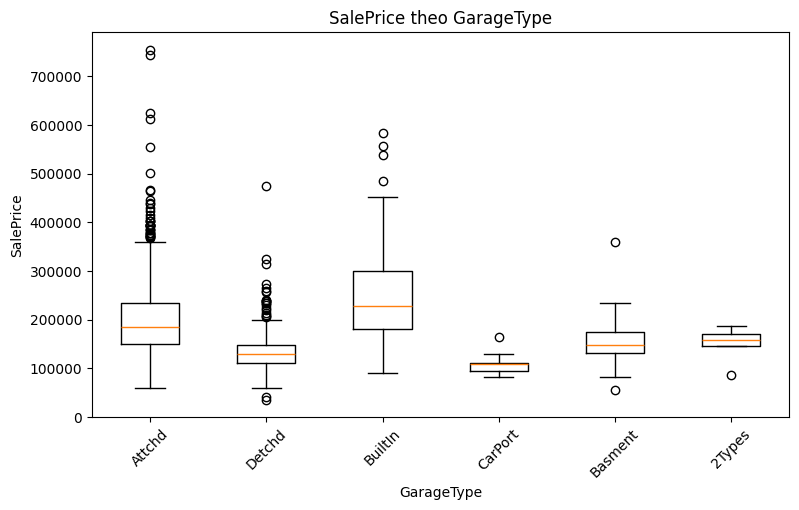

In [119]:
import matplotlib.pyplot as plt

groups = train['GarageType'].dropna().unique()

data = [
    train[train['GarageType'] == group]['SalePrice'].dropna()
    for group in groups
]

plt.figure(figsize=(9, 5))

plt.boxplot(data, labels=groups)

plt.title('SalePrice theo GarageType')
plt.xlabel('GarageType')
plt.ylabel('SalePrice')

plt.xticks(rotation=45)

plt.show()

In [120]:
stats_overallqual = train.groupby('OverallQual')['SalePrice'].agg(
    ['count', 'mean', 'median']
).round(2)

stats_overallqual

,count,mean,median
OverallQual,,,
1,2,50150.00,50150.0
2,3,51770.33,60000.0
3,20,87473.75,86250.0
4,116,108420.66,108000.0
5,397,133523.35,133000.0
6,374,161603.03,160000.0
7,319,207716.42,200141.0
8,168,274735.54,269750.0
9,43,367513.02,345000.0


In [121]:
table_housestyle_bldgtype = pd.crosstab(
    train['HouseStyle'],
    train['BldgType']
)

table_housestyle_bldgtype

BldgType,1Fam,2fmCon,Duplex,Twnhs,TwnhsE
HouseStyle,,,,,
1.5Fin,142,8,4,0,0
1.5Unf,13,1,0,0,0
1Story,607,7,29,5,78
2.5Fin,7,1,0,0,0
2.5Unf,9,2,0,0,0
2Story,362,11,9,33,30
SFoyer,20,0,9,4,4
SLvl,60,1,1,1,2


In [122]:
table_housestyle_bldgtype_pct = pd.crosstab(
    train['HouseStyle'],
    train['BldgType'],
    normalize='index'
) * 100

table_housestyle_bldgtype_pct.round(2)

BldgType,1Fam,2fmCon,Duplex,Twnhs,TwnhsE
HouseStyle,,,,,
1.5Fin,92.21,5.19,2.60,0.00,0.00
1.5Unf,92.86,7.14,0.00,0.00,0.00
1Story,83.61,0.96,3.99,0.69,10.74
2.5Fin,87.50,12.50,0.00,0.00,0.00
2.5Unf,81.82,18.18,0.00,0.00,0.00
2Story,81.35,2.47,2.02,7.42,6.74
SFoyer,54.05,0.00,24.32,10.81,10.81
SLvl,92.31,1.54,1.54,1.54,3.08


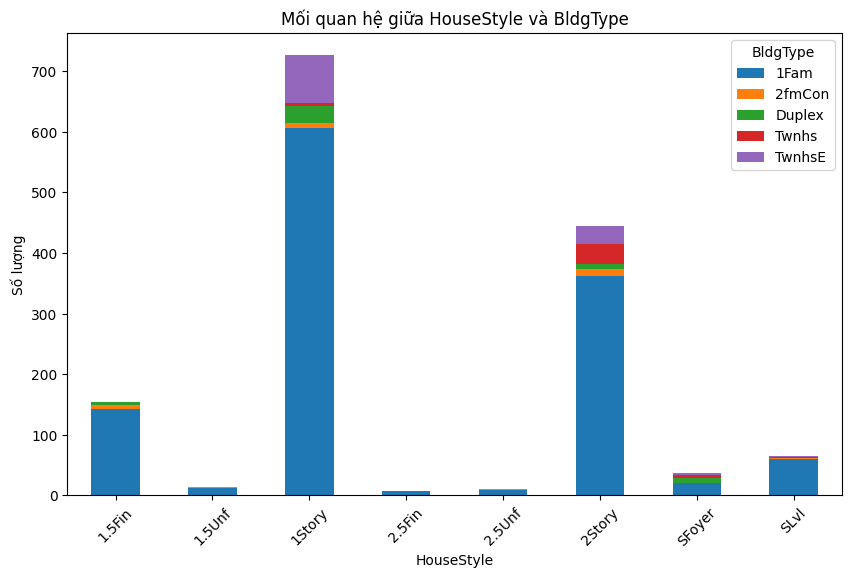

In [123]:
table_housestyle_bldgtype.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Mối quan hệ giữa HouseStyle và BldgType')
plt.xlabel('HouseStyle')
plt.ylabel('Số lượng')
plt.xticks(rotation=45)

plt.show()

In [124]:
before_shape = train.shape

print("Kích thước trước preprocessing:", before_shape)

Kích thước trước preprocessing: (1460, 81)


In [125]:
table_garage = pd.crosstab(
    train['GarageType'],
    train['GarageFinish']
)

table_garage

GarageFinish,Fin,RFn,Unf
GarageType,,,
2Types,1,2,3
Attchd,274,371,225
Basment,4,6,9
BuiltIn,59,24,5
CarPort,0,0,9
Detchd,14,19,354


In [126]:
table_garage_pct = pd.crosstab(
    train['GarageType'],
    train['GarageFinish'],
    normalize='index'
) * 100

table_garage_pct.round(2)

GarageFinish,Fin,RFn,Unf
GarageType,,,
2Types,16.67,33.33,50.00
Attchd,31.49,42.64,25.86
Basment,21.05,31.58,47.37
BuiltIn,67.05,27.27,5.68
CarPort,0.00,0.00,100.00
Detchd,3.62,4.91,91.47


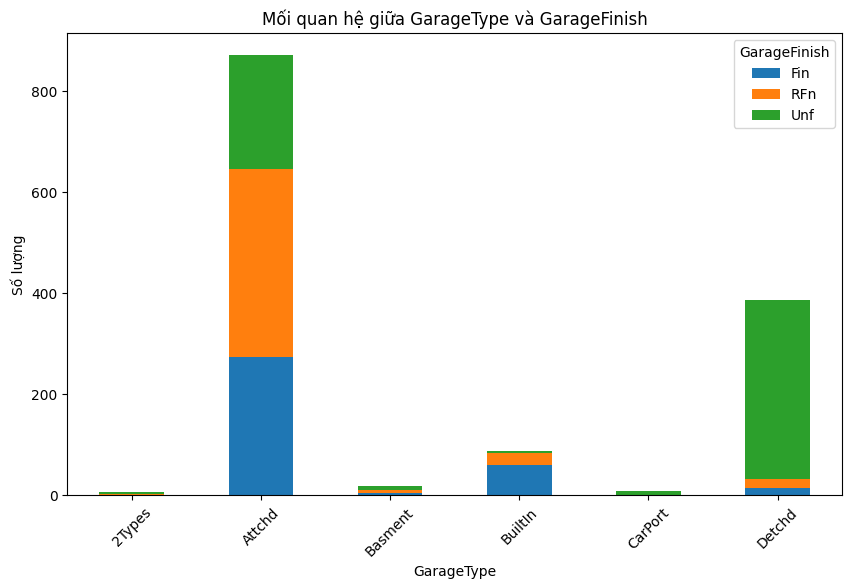

In [127]:
table_garage.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Mối quan hệ giữa GarageType và GarageFinish')
plt.xlabel('GarageType')
plt.ylabel('Số lượng')
plt.xticks(rotation=45)

plt.show()

In [128]:
Q1 = train['SalePrice'].quantile(0.25)
Q3 = train['SalePrice'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Lower bound: 3937.5
Upper bound: 340037.5


In [129]:
outliers_saleprice = train[
    (train['SalePrice'] < lower_bound) |
    (train['SalePrice'] > upper_bound)
]

print("Số mẫu bất thường:", len(outliers_saleprice))
outliers_saleprice[['Id', 'SalePrice']]

Số mẫu bất thường: 61


,Id,SalePrice
11,12,345000
53,54,385000
58,59,438780
112,113,383970
151,152,372402
...,...,...
1268,1269,381000
1353,1354,410000
1373,1374,466500
1388,1389,377500


In [130]:
Q1 = train['SalePrice'].quantile(0.25)
Q3 = train['SalePrice'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Ngưỡng dưới:", lower_bound)
print("Ngưỡng trên:", upper_bound)

Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Ngưỡng dưới: 3937.5
Ngưỡng trên: 340037.5


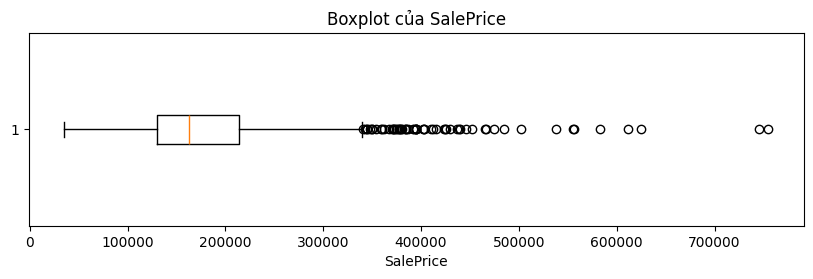

In [131]:
plt.figure(figsize=(10, 2.5))

plt.boxplot(train['SalePrice'], vert=False)

plt.title('Boxplot của SalePrice')
plt.xlabel('SalePrice')

plt.show()

In [132]:
outliers = train[
    (train['SalePrice'] < lower_bound) |
    (train['SalePrice'] > upper_bound)
]

print("Số lượng mẫu bất thường:", len(outliers))

outliers[['Id', 'SalePrice']]

Số lượng mẫu bất thường: 61


,Id,SalePrice
11,12,345000
53,54,385000
58,59,438780
112,113,383970
151,152,372402
...,...,...
1268,1269,381000
1353,1354,410000
1373,1374,466500
1388,1389,377500


In [133]:
Q1 = train['GrLivArea'].quantile(0.25)
Q3 = train['GrLivArea'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Ngưỡng dưới:", lower_bound)
print("Ngưỡng trên:", upper_bound)

Q1: 1129.5
Q3: 1776.75
IQR: 647.25
Ngưỡng dưới: 158.625
Ngưỡng trên: 2747.625


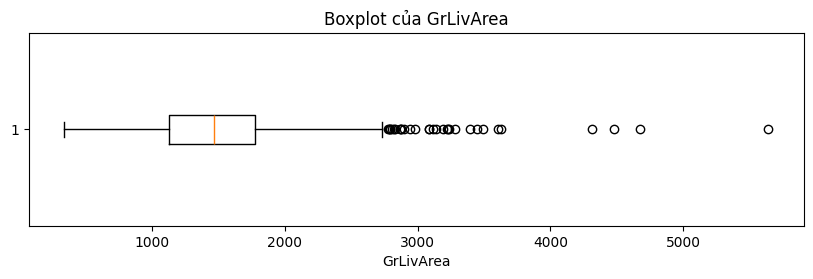

In [134]:
plt.figure(figsize=(10, 2.5))

plt.boxplot(train['GrLivArea'], vert=False)

plt.title('Boxplot của GrLivArea')
plt.xlabel('GrLivArea')

plt.show()

In [135]:
outliers_grlivarea = train[
    (train['GrLivArea'] < lower_bound) |
    (train['GrLivArea'] > upper_bound)
]

print("Số lượng mẫu bất thường:", len(outliers_grlivarea))

outliers_grlivarea[['Id', 'GrLivArea', 'SalePrice']]

Số lượng mẫu bất thường: 31


,Id,GrLivArea,SalePrice
58,59,2945,438780
118,119,3222,320000
185,186,3608,475000
197,198,3112,235000
231,232,2794,403000
304,305,3493,295000
324,325,2978,242000
496,497,3228,430000
523,524,4676,184750
583,584,2775,325000


In [136]:
from scipy.stats import zscore

train['SalePrice_Zscore'] = zscore(train['SalePrice'])

print(train[['Id', 'SalePrice', 'SalePrice_Zscore']].head())

   Id  SalePrice  SalePrice_Zscore
0   1     208500          0.347273
1   2     181500          0.007288
2   3     223500          0.536154
3   4     140000         -0.515281
4   5     250000          0.869843


In [137]:
zscore_outliers = train[train['SalePrice_Zscore'].abs() > 3]

print("Số lượng mẫu bất thường:", len(zscore_outliers))

zscore_outliers[['Id', 'SalePrice', 'SalePrice_Zscore']]

Số lượng mẫu bất thường: 22


,Id,SalePrice,SalePrice_Zscore
58,59,438780,3.246967
178,179,501837,4.040982
185,186,475000,3.703050
349,350,437154,3.226492
389,390,426000,3.086040
440,441,555000,4.710413
473,474,440000,3.262329
496,497,430000,3.136409
527,528,446261,3.341168
591,592,451950,3.412804


In [138]:
Q1 = train['SalePrice'].quantile(0.25)
Q3 = train['SalePrice'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = train[
    (train['SalePrice'] < lower_bound) |
    (train['SalePrice'] > upper_bound)
]

print("Số lượng outlier theo IQR:", len(iqr_outliers))
print("Số lượng outlier theo Z-score:", len(zscore_outliers))

Số lượng outlier theo IQR: 61
Số lượng outlier theo Z-score: 22


In [139]:
comparison = pd.DataFrame({
    'Phương pháp': ['IQR', 'Z-score'],
    'Tiêu chí': [
        'Ngoài Q1 - 1.5×IQR hoặc Q3 + 1.5×IQR',
        '|Z-score| > 3'
    ],
    'Số lượng outlier': [
        len(iqr_outliers),
        len(zscore_outliers)
    ]
})

comparison

,Phương pháp,Tiêu chí,Số lượng outlier
0,IQR,Ngoài Q1 - 1.5×IQR hoặc Q3 + 1.5×IQR,61
1,Z-score,|Z-score| > 3,22


In [140]:
import pandas as pd

columns = [
    'SalePrice',
    'GrLivArea',
    'LotArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'GarageArea'
]

iqr_result = []

for col in columns:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = train[(train[col] < lower_bound) | (train[col] > upper_bound)]
    
    iqr_result.append([
        col,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        len(outliers)
    ])

iqr_df = pd.DataFrame(
    iqr_result,
    columns=[
        'Feature',
        'Q1',
        'Q3',
        'IQR',
        'Lower Bound',
        'Upper Bound',
        'Số lượng Outlier'
    ]
)

iqr_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Số lượng Outlier
0,SalePrice,129975.00,214000.00,84025.00,3937.500,340037.500,61
1,GrLivArea,1129.50,1776.75,647.25,158.625,2747.625,31
2,LotArea,7553.50,11601.50,4048.00,1481.500,17673.500,69
3,TotalBsmtSF,795.75,1298.25,502.50,42.000,2052.000,61
4,1stFlrSF,882.00,1391.25,509.25,118.125,2155.125,20
5,GarageArea,334.50,576.00,241.50,-27.750,938.250,21


In [141]:
from scipy.stats import zscore

columns = [
    'SalePrice',
    'GrLivArea',
    'LotArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'GarageArea'
]

zscore_result = []

for col in columns:
    z = zscore(train[col])
    outliers = train[abs(z) > 3]
    
    zscore_result.append([
        col,
        len(outliers)
    ])

zscore_df = pd.DataFrame(
    zscore_result,
    columns=['Feature', 'Số lượng Outlier']
)

zscore_df

,Feature,Số lượng Outlier
0,SalePrice,22
1,GrLivArea,16
2,LotArea,13
3,TotalBsmtSF,10
4,1stFlrSF,12
5,GarageArea,7


C:\Users\admin\AppData\Local\Temp\ipykernel_27020\4054987180.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


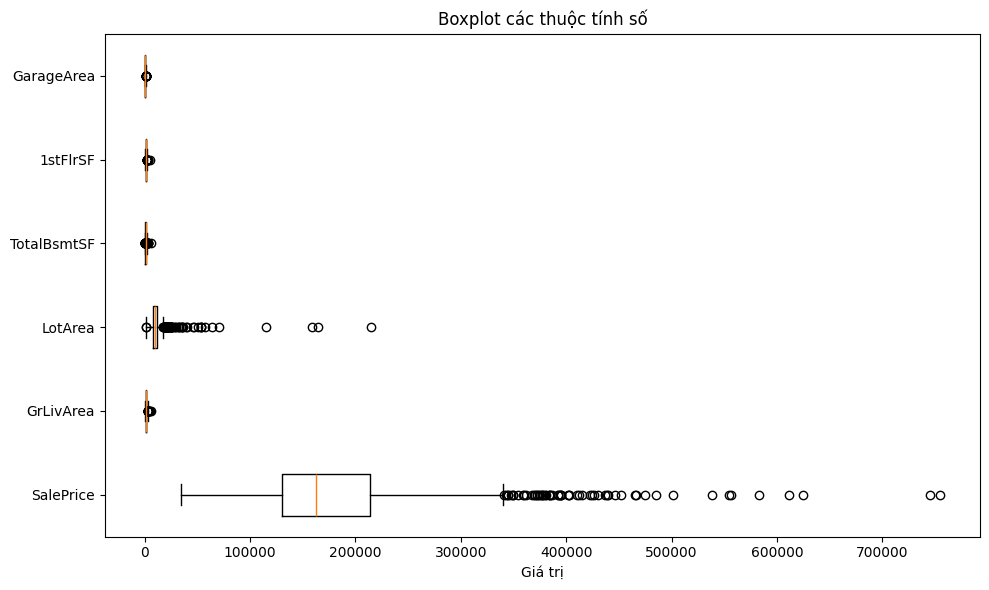

In [142]:
columns = [
    'SalePrice',
    'GrLivArea',
    'LotArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'GarageArea'
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    [train[col] for col in columns],
    labels=columns,
    vert=False
)

plt.title('Boxplot các thuộc tính số')
plt.xlabel('Giá trị')

plt.tight_layout()
plt.show()

In [143]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)
num_cols = train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = train.select_dtypes(include=['object']).columns
train[num_cols] = train[num_cols].fillna(train[num_cols].median())
train[cat_cols] = train[cat_cols].fillna(train[cat_cols].mode().iloc[0])
print(train.isnull().sum().sum())

C:\Users\admin\AppData\Local\Temp\ipykernel_27020\339928965.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train.select_dtypes(include=['object']).columns


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64
0


In [144]:
abnormal = train[
    (train['GrLivArea'] > 4000) &
    (train['SalePrice'] < 300000)
]

print(abnormal[['Id', 'GrLivArea', 'SalePrice']])
train = train.drop(abnormal.index)
print(train.shape)
abnormal_check = train[
    (train['GrLivArea'] > 4000) &
    (train['SalePrice'] < 300000)
]

print(abnormal_check)

        Id  GrLivArea  SalePrice
523    524       4676     184750
1298  1299       5642     160000
(1458, 82)
Empty DataFrame
Columns: [Id, MSSubClass, MSZoning, LotFrontage, LotArea, Street, Alley, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, OverallQual, OverallCond, YearBuilt, YearRemodAdd, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, MasVnrArea, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinSF1, BsmtFinType2, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, Heating, HeatingQC, CentralAir, Electrical, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, KitchenQual, TotRmsAbvGrd, Functional, Fireplaces, FireplaceQu, GarageType, GarageYrBlt, GarageFinish, GarageCars, GarageArea, GarageQual, GarageCond, PavedDrive, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, PoolQC, Fence, Mi

In [145]:
Q1 = train['SalePrice'].quantile(0.25)
Q3 = train['SalePrice'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = train[
    (train['SalePrice'] < lower) |
    (train['SalePrice'] > upper)
]

print(outliers[['Id', 'SalePrice']])

        Id  SalePrice
11      12     345000
53      54     385000
58      59     438780
112    113     383970
151    152     372402
...    ...        ...
1268  1269     381000
1353  1354     410000
1373  1374     466500
1388  1389     377500
1437  1438     394617

[61 rows x 2 columns]


In [146]:
after_shape = train.shape

print("Kích thước sau preprocessing:", after_shape)

Kích thước sau preprocessing: (1458, 82)
